# Model 3 – Random Forest Fraud Detection

This notebook implements the third machine learning model for the fraud detection project.

Model: Random Forest Classifier

The objective is to train the model on three datasets:

- ULB Credit Card Dataset
- IEEE Fraud Dataset
- PaySim Dataset

Libraries used:
- pandas
- scikit-learn
- matplotlib

The notebook performs:
1. Data loading
2. Preprocessing
3. Model training
4. Performance evaluation
5. Visualization
6. Model saving

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc

In [2]:
ulb = pd.read_csv("../data/processed/processed_ulb_dataset.csv")
ieee = pd.read_csv("../data/processed/processed_ieee_dataset.csv")
paysim = pd.read_csv("../data/processed/processed_paysim_dataset.csv")

print("Datasets Loaded Successfully")

print("ULB Shape:", ulb.shape)
print("IEEE Shape:", ieee.shape)
print("PaySim Shape:", paysim.shape)

Datasets Loaded Successfully
ULB Shape: (283726, 31)
IEEE Shape: (590540, 434)
PaySim Shape: (6362620, 11)


In [6]:
def train_random_forest(data, target_column):

    X = data.drop(target_column, axis=1)
    y = data[target_column]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    return model, accuracy, X_test, y_test, predictions

In [7]:
rf_ulb, acc_ulb, X_ulb, y_ulb, pred_ulb = train_random_forest(
    ulb,
    "Class"
)

rf_ieee, acc_ieee, X_ieee, y_ieee, pred_ieee = train_random_forest(
    ieee,
    "isFraud"
)

rf_paysim, acc_paysim, X_paysim, y_paysim, pred_paysim = train_random_forest(
    paysim,
    "isFraud"
)

print("Training completed")
print()

print("ULB Accuracy:", acc_ulb)
print("IEEE Accuracy:", acc_ieee)
print("PaySim Accuracy:", acc_paysim)

Training completed

ULB Accuracy: 0.9995418179254926
IEEE Accuracy: 0.9792901412266739
PaySim Accuracy: 0.9997060959164621


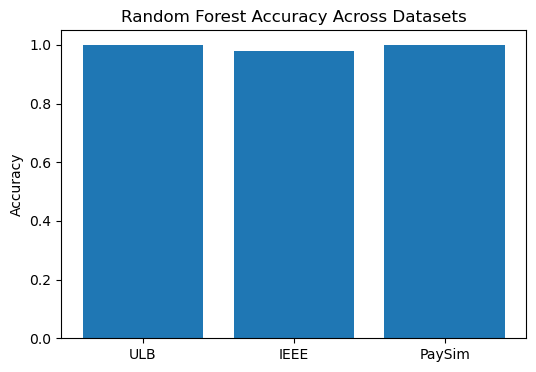

In [8]:
accuracies = {
    "ULB": acc_ulb,
    "IEEE": acc_ieee,
    "PaySim": acc_paysim
}

plt.figure(figsize=(6,4))

plt.bar(accuracies.keys(), accuracies.values())

plt.title("Random Forest Accuracy Across Datasets")

plt.ylabel("Accuracy")

plt.show()

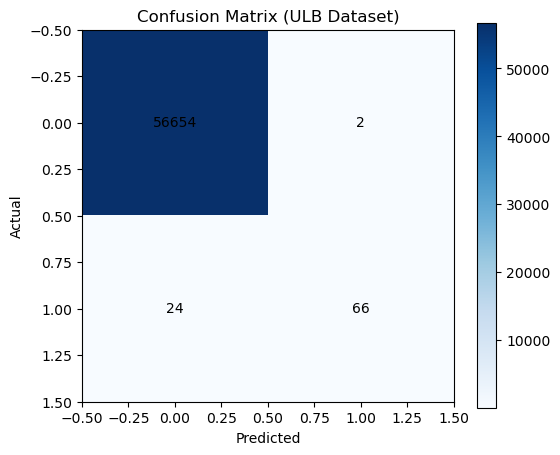

In [17]:
cm = confusion_matrix(y_ulb, pred_ulb)

plt.figure(figsize=(6,5))

plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix (ULB Dataset)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i][j], ha="center", va="center")

plt.colorbar()

plt.show()

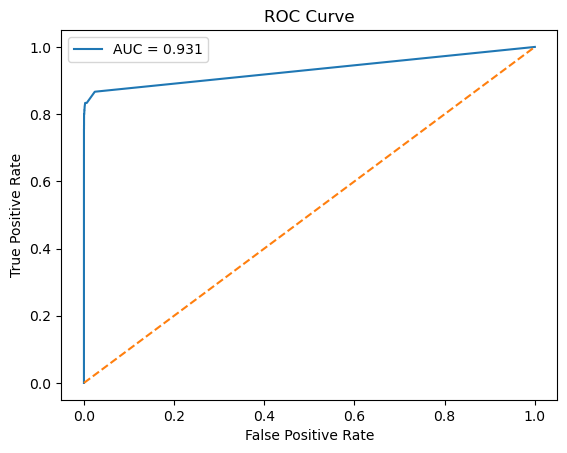

In [18]:
y_prob = rf_ulb.predict_proba(X_ulb)[:,1]

fpr, tpr, _ = roc_curve(y_ulb, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure()

plt.plot(fpr, tpr, label="AUC = %0.3f" % roc_auc)

plt.plot([0,1],[0,1],'--')

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

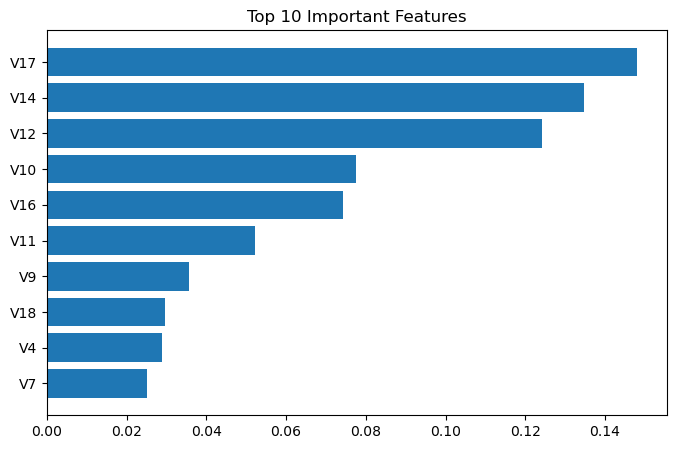

In [19]:
importance = rf_ulb.feature_importances_

features = X_ulb.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(8,5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [20]:
joblib.dump(rf_ulb, "../results/models/random_forest_ulb.pkl")
joblib.dump(rf_ieee, "../results/models/random_forest_ieee.pkl")
joblib.dump(rf_paysim, "../results/models/random_forest_paysim.pkl")

print("Models saved successfully")

Models saved successfully
